# Cycle 2 — SDG 7: Southern Asia, One Level Down

**Question:** *Cycle 1 ranked Central and Southern Asia as the second-fastest narrowing region
(−12.7 pp). Was that the region, or was it India?*

Cycle 1 found a region moving the wrong way inside a world moving the right way. Cycle 2 inverts
the same move one level down: countries moving the wrong way inside a region moving the right
way. Three findings, one figure each.

| | Finding | Figure |
|---|---|---|
| **A** | The region's gap fell 12 points; its average country's did not move | `01_weighted_vs_average.png` |
| **B** | Electricity equalised town and village; clean cooking did not | `02_urban_rural_split.png` |
| **C** | The renewable-share indicator is partly counting firewood | `03_renewables_paradox.png` |

Tables come from `01_derive_southern_asia.py`, which reads Cycle 1's outputs and copies nothing.
**Key metric** is unchanged from Cycle 1: `cooking_gap = electricity % − clean cooking %`, in
percentage points. A *positive* gap means electricity is ahead; a *negative change* means the gap
narrowed.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

PROC = Path.cwd().parent / "data" / "processed"
FIGS = Path.cwd().parent / "outputs" / "matplotlib_figures"
FIGS.mkdir(parents=True, exist_ok=True)

# Same palette as Cycle 1, so the two decks read as one system. Blue and orange are the
# only two categorical hues used here: validated at dE 33.6 normal / 24.7 protan. The
# palette's red is NOT used alongside orange -- the pair is only dE 7.1 apart in normal
# vision, which is below the legibility floor. Where a third series is needed, it is
# carried by line weight and a direct label in ink, not by a third hue.
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#8a8a85", "#e5e4e0"
GRAY = "#c3c2bd"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRID, "axes.linewidth": 0.8,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "axes.labelsize": 9.5, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2,
    "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRID, "grid.linewidth": 0.7,
    "legend.frameon": False, "legend.fontsize": 9,
    "font.size": 10,
})

SOURCE = "UN SDG Global Indicators Database (API v5) · 7.1.1 World Bank · 7.1.2 WHO GHO"

def finish(ax, title, subtitle=None, source=SOURCE, note=None, foot_y=-0.04):
    '''Title states the finding; subtitle carries the detail; source always cited.'''
    ax.set_title(title, loc="left", pad=18 if subtitle else 10)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=9.5,
                color=INK2, va="bottom")
    y = foot_y
    if note:
        ax.figure.text(0.0, y, note, fontsize=7.5, color=INK2, ha="left")
        y -= 0.05
    ax.figure.text(0.0, y, source, fontsize=7.5, color=MUTED, ha="left")

ELEC, COOK = "EG_ACS_ELEC", "EG_EGY_CLEAN"
country_year = pd.read_csv(PROC / "sa_country_year.csv")
summary = pd.read_csv(PROC / "sa_country_summary.csv")
subregion = pd.read_csv(PROC / "sa_subregion_year.csv")
cross = pd.read_csv(PROC / "rnew_vs_cooking_2023.csv")
print(f"{len(country_year)} country-years · {len(summary)} countries · "
      f"{len(cross)} countries in the 2023 cross-section")

90 country-years · 9 countries · 192 countries in the 2023 cross-section


## A. Was it the region, or was it India?

Two ways of averaging the *same nine countries*. The UN's regional figure is
population-weighted, so every person counts once — which lets India's 1.4 billion set the
number. The unweighted average counts every country once.

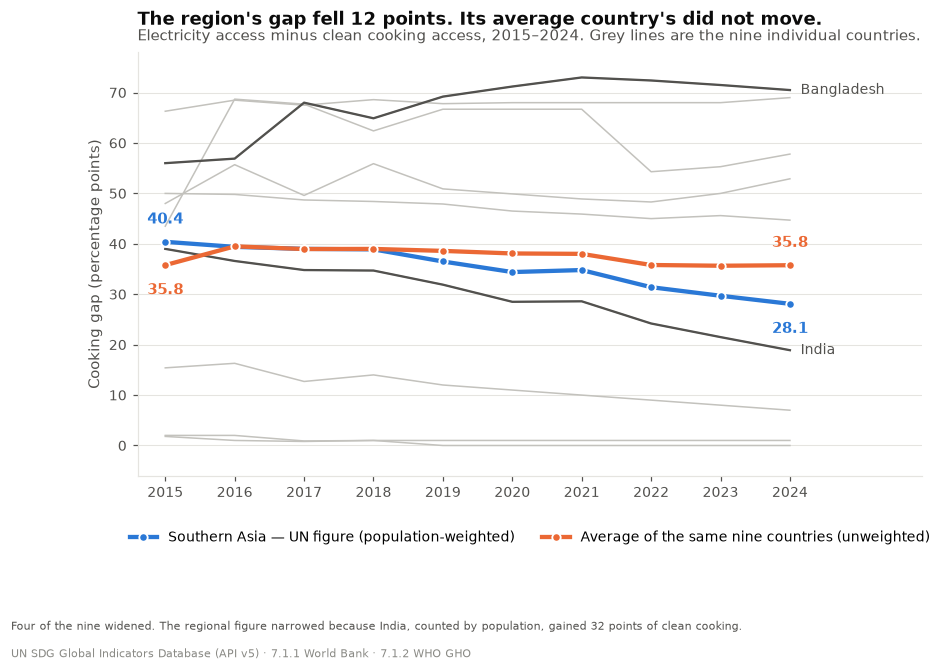

UN weighted       40.4 ->  28.1  (-12.3 pp)
unweighted mean   35.8 ->  35.8  (-0.0 pp)
widened: 4 of 9 — Bangladesh, Sri Lanka, Afghanistan, Nepal


In [2]:
gaps = country_year.pivot(index="year", columns="country", values="cooking_gap")
weighted = subregion[subregion.area == "Southern Asia"].set_index("year").gap.sort_index()
average = (subregion[subregion.area == "Southern Asia (unweighted mean)"]
           .set_index("year").gap.sort_index())

fig, ax = plt.subplots(figsize=(9.2, 5.0))

# The nine countries as context. No hue -- they are the backdrop the two lines summarise.
for c in gaps.columns:
    ax.plot(gaps.index, gaps[c], color=GRAY, lw=1.0, zorder=1)

# The two extremes earn a name. Identity is weight + direct label, never a third hue.
for country in ("Bangladesh", "India"):
    ax.plot(gaps.index, gaps[country], color=INK2, lw=1.5, zorder=2)
    ax.annotate(country, (gaps.index[-1], gaps[country].iloc[-1]),
                xytext=(7, 0), textcoords="offset points",
                fontsize=9, color=INK2, va="center")

ax.plot(weighted.index, weighted, color=BLUE, lw=2.8, marker="o", ms=5.5, zorder=4,
        markeredgecolor="white", markeredgewidth=1.2,
        label="Southern Asia — UN figure (population-weighted)")
ax.plot(average.index, average, color=ORANGE, lw=2.8, marker="o", ms=5.5, zorder=4,
        markeredgecolor="white", markeredgewidth=1.2,
        label="Average of the same nine countries (unweighted)")

# Whichever line is higher in a given year gets its value above, the other below,
# so the two endpoint labels can never collide where the lines cross.
for year in (2015, 2024):
    for line, color in ((weighted, BLUE), (average, ORANGE)):
        above = line[year] >= (average[year] if color == BLUE else weighted[year])
        ax.annotate(f"{line[year]:.1f}", (year, line[year]),
                    xytext=(0, 12 if above else -19), textcoords="offset points",
                    fontsize=9.5, fontweight="bold", color=color, ha="center")

ax.set_ylim(-6, 78)
ax.set_xlim(2014.6, 2025.9)
ax.set_xticks(range(2015, 2025))
ax.set_ylabel("Cooking gap (percentage points)")
ax.grid(axis="y"); ax.set_axisbelow(True)
# Below the axes: the top-right is where Bangladesh ends, and a legend there
# printed straight over its label.
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.10), ncol=2)
finish(ax,
       "The region's gap fell 12 points. Its average country's did not move.",
       "Electricity access minus clean cooking access, 2015–2024. Grey lines are the nine "
       "individual countries.",
       note="Four of the nine widened. The regional figure narrowed because India, counted "
            "by population, gained 32 points of clean cooking.",
       foot_y=-0.17)
plt.savefig(FIGS / "01_weighted_vs_average.png"); plt.show()

print(f"UN weighted      {weighted[2015]:5.1f} -> {weighted[2024]:5.1f}  "
      f"({weighted[2024]-weighted[2015]:+.1f} pp)")
print(f"unweighted mean  {average[2015]:5.1f} -> {average[2024]:5.1f}  "
      f"({average[2024]-average[2015]:+.1f} pp)")
print(f"widened: {(summary.gap_change > 0).sum()} of {len(summary)} — "
      f"{', '.join(summary[summary.gap_change > 0].country)}")

**Finding.** The region's gap fell 12.3 points while the unweighted average of its nine
countries moved −0.0. India gained 32 points of clean cooking (3.56 pp/yr, the fastest of the
nine) and carries enough of the region's population to set the regional figure by itself. Four
of the nine countries moved the *other* way: Bangladesh +14.5, Afghanistan +14.3, Nepal +4.9,
Sri Lanka +2.7.

*Why the mean and not the median:* with nine countries the median is a single country, and the
2015 median is Afghanistan — whose electricity series jumps 71.5 → 97.7 between 2015 and 2016, a
revision rather than real change. Excluding Afghanistan moves the median's decade change from
+1.2 to −11.7 pp, but moves the mean only from −0.0 to −1.8. Only the mean supports the claim
either way.

## B. Where the remaining deficit sits

The regional figure cannot see inside a country. Both access indicators carry a Location
dimension, so urban and rural can be compared directly for 2024.

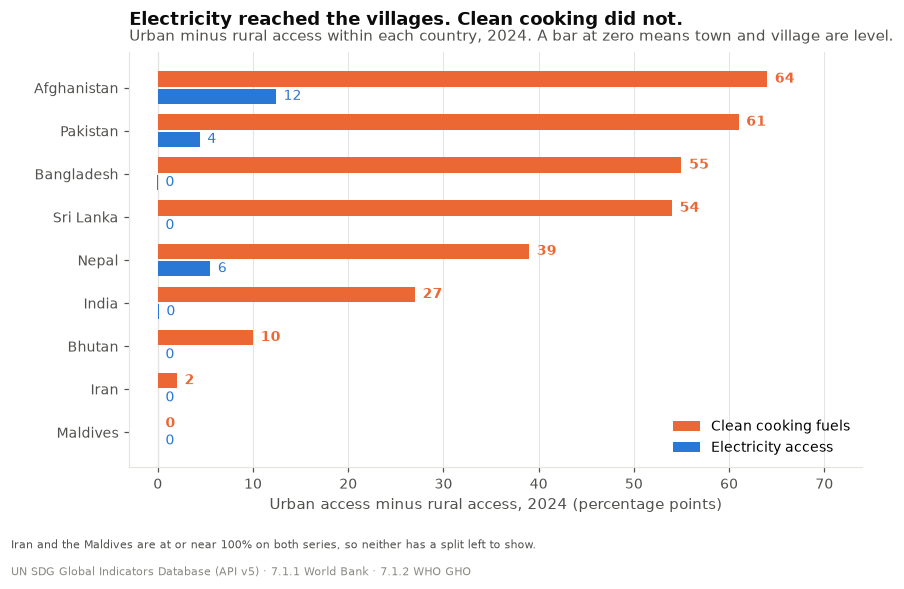

electricity split under 2 pp: 6 of 9 countries
cooking split over 25 pp:     6 of 9 countries
  Afghanistan                 cooking split is  5.2x the electricity split
  Pakistan                    cooking split is 13.9x the electricity split
  Nepal                       cooking split is  7.1x the electricity split


In [3]:
order = summary.sort_values("cook_urban_rural_gap_2024")
y = np.arange(len(order))
h = 0.36                      # leaves a surface gap between the paired bars

fig, ax = plt.subplots(figsize=(8.6, 4.9))
ax.barh(y + h / 2 + 0.02, order.cook_urban_rural_gap_2024, height=h, color=ORANGE,
        label="Clean cooking fuels", zorder=3)
ax.barh(y - h / 2 - 0.02, order.elec_urban_rural_gap_2024, height=h, color=BLUE,
        label="Electricity access", zorder=3)

for yi, (_, r) in zip(y, order.iterrows()):
    ax.annotate(f"{r.cook_urban_rural_gap_2024:.0f}",
                (r.cook_urban_rural_gap_2024, yi + h / 2 + 0.02),
                xytext=(5, 0), textcoords="offset points", fontsize=9,
                fontweight="bold", color=ORANGE, va="center")
    elec = r.elec_urban_rural_gap_2024
    # Bangladesh is -0.1 (rural marginally ahead), which "%.0f" renders as "-0".
    elec_label = f"{elec:.0f}".replace("-0", "0")
    ax.annotate(elec_label, (max(elec, 0), yi - h / 2 - 0.02),
                xytext=(5, 0), textcoords="offset points", fontsize=9,
                color=BLUE, va="center")

ax.axvline(0, color=GRID, lw=0.9, zorder=1)
ax.set_yticks(y)
ax.set_yticklabels([c.replace(" (Islamic Republic of)", "") for c in order.country])
ax.set_xlim(-3, 74)
ax.set_xlabel("Urban access minus rural access, 2024 (percentage points)")
ax.grid(axis="x"); ax.set_axisbelow(True)
ax.legend(loc="lower right")
finish(ax,
       "Electricity reached the villages. Clean cooking did not.",
       "Urban minus rural access within each country, 2024. A bar at zero means town and "
       "village are level.",
       note="Iran and the Maldives are at or near 100% on both series, so neither has a split "
            "left to show.")
plt.savefig(FIGS / "02_urban_rural_split.png"); plt.show()

below = summary[~summary.cook_at_ceiling]
print(f"electricity split under 2 pp: "
      f"{(summary.elec_urban_rural_gap_2024.abs() < 2).sum()} of {len(summary)} countries")
print(f"cooking split over 25 pp:     "
      f"{(summary.cook_urban_rural_gap_2024 > 25).sum()} of {len(summary)} countries")
for _, r in below.sort_values("cook_urban_rural_gap_2024", ascending=False).iterrows():
    if r.elec_urban_rural_gap_2024 > 0.5:
        print(f"  {r.country[:26]:<27} cooking split is "
              f"{r.cook_urban_rural_gap_2024 / r.elec_urban_rural_gap_2024:4.1f}x "
              f"the electricity split")

**Finding.** Electrification equalised town and village: the urban–rural electricity gap is
under 2 pp in six of the nine countries, and in Bangladesh it is *negative* (−0.1). Clean cooking
did not: Afghanistan 64 pp, Pakistan 61, Bangladesh 55, Sri Lanka 54, Nepal 39, India 27.
Pakistan's cooking split is **14×** its electricity split.

This is Cycle 1's Zimbabwe slide (80% urban, 8% rural) generalised — there it was one country's
anecdote, here it is every country in the region with a deficit left to have. The grid solved
geography. The stove did not.

## C. What the renewable-share indicator is counting

SDG 7 has a second target, 7.2 — the renewable share of final energy consumption. It counts
*all* renewables, and traditional solid biomass (firewood, charcoal, dung) is renewable. So the
same fuel that fails indicator 7.1.2 scores for indicator 7.2.1.

Anchored to 2023, the last year with full coverage: 7.2.1 has 226 countries through 2023 and only
84 in 2024, because the IEA/UNSD energy balances lag the access series.

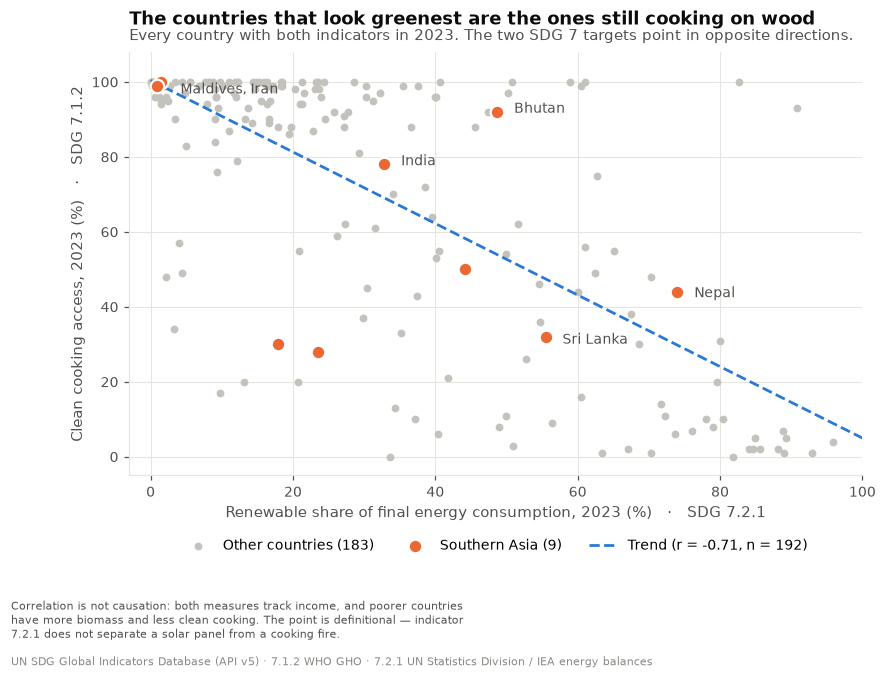

pearson -0.711 · spearman -0.644 · n = 192
                   country  renewable_share  clean_cooking
                     Nepal            74.02           44.0
                 Sri Lanka            55.50           32.0
                    Bhutan            48.71           92.0
                  Pakistan            44.14           50.0
                     India            32.84           78.0
                Bangladesh            23.56           28.0
               Afghanistan            17.89           30.0
                  Maldives             1.40          100.0
Iran (Islamic Republic of)             0.92           99.0


In [4]:
other = cross[~cross.in_southern_asia]
south = cross[cross.in_southern_asia]
pearson = cross.renewable_share.corr(cross.clean_cooking)
spearman = cross.renewable_share.corr(cross.clean_cooking, method="spearman")

fig, ax = plt.subplots(figsize=(8.6, 5.0))
ax.scatter(other.renewable_share, other.clean_cooking, s=26, color=GRAY,
           lw=0, zorder=2, label=f"Other countries ({len(other)})")
ax.scatter(south.renewable_share, south.clean_cooking, s=78, color=ORANGE,
           edgecolor="white", lw=1.4, zorder=4, label=f"Southern Asia ({len(south)})")

fit = np.polyfit(cross.renewable_share, cross.clean_cooking, 1)
xs = np.linspace(0, 100, 50)
ax.plot(xs, np.polyval(fit, xs), color=BLUE, lw=1.8, ls="--", zorder=3,
        label=f"Trend (r = {pearson:.2f}, n = {len(cross)})")

# Manual offsets: the Maldives and Iran sit almost on top of each other, so they share
# one label rather than overprinting two.
# Selective labels: the five the finding actually names. Afghanistan, Bangladesh and
# Pakistan sit in the crowded middle of the cloud, where a label lands nearer a grey
# dot than its own orange one -- they stay identified by the legend instead.
offsets = {"Nepal": (11, -1), "Sri Lanka": (11, -2), "Bhutan": (11, 2),
           "India": (11, 2), "Maldives": (13, -5)}
for _, r in south.iterrows():
    name = r.country
    if name not in offsets:
        continue
    label = "Maldives, Iran" if name == "Maldives" else name
    dx, dy = offsets[name]
    ax.annotate(label, (r.renewable_share, r.clean_cooking), xytext=(dx, dy),
                textcoords="offset points", fontsize=9, color=INK2,
                ha="left" if dx > 0 else "right", va="center", zorder=5)

ax.set_xlim(-3, 100); ax.set_ylim(-5, 108)
ax.set_xlabel("Renewable share of final energy consumption, 2023 (%)   ·   SDG 7.2.1")
ax.set_ylabel("Clean cooking access, 2023 (%)   ·   SDG 7.1.2")
ax.grid(True); ax.set_axisbelow(True)
# Below the axes: the upper right holds real data points, and a frameless legend
# there sits on top of them.
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
finish(ax,
       "The countries that look greenest are the ones still cooking on wood",
       "Every country with both indicators in 2023. The two SDG 7 targets point in opposite "
       "directions.",
       note="Correlation is not causation: both measures track income, and poorer countries\n"
            "have more biomass and less clean cooking. The point is definitional — indicator\n"
            "7.2.1 does not separate a solar panel from a cooking fire.",
       foot_y=-0.185,
       source="UN SDG Global Indicators Database (API v5) · 7.1.2 WHO GHO · "
              "7.2.1 UN Statistics Division / IEA energy balances")
plt.savefig(FIGS / "03_renewables_paradox.png"); plt.show()

print(f"pearson {pearson:.3f} · spearman {spearman:.3f} · n = {len(cross)}")
print(south[["country", "renewable_share", "clean_cooking"]]
      .sort_values("renewable_share", ascending=False).to_string(index=False))

**Finding.** Across 192 countries the two SDG 7 indicators move in opposite directions:
Pearson **−0.71**, Spearman **−0.64**, so this is not one or two outliers dragging a line.
Southern Asia spans the whole range and illustrates it by itself — Nepal is 74% "renewable" with
44% clean cooking; Sri Lanka 55% with 32%; against the Maldives at 1.4% renewable and 100% clean
cooking.

Sri Lanka is the sharpest case in the region: universal electricity, 55% renewable energy, and
clean cooking at 31% — level with Afghanistan, and with **no net gain since 2018**.

**The honest caveat**, which belongs on the slide: both measures track income, so this
correlation is confounded and is not evidence that renewables harm cooking. The claim is
definitional — indicator 7.2.1 does not distinguish a solar panel from a cooking fire, so a
country can improve its SDG 7.2 score by burning more wood.

---

### Still to do (Phase 3)

Not findings, so they are written against the figures rather than given slides of their own:

- **D — the 2030 pace check.** Only India, Bhutan and the Maldives reach universal clean cooking
  on the 2015–2024 trend. Bangladesh projects to 36.7%, Sri Lanka 33.2%, Afghanistan 31.1%.
  Columns already exist in `sa_country_summary.csv`; one closing line, no chart.
- **E — Sri Lanka.** Folded into Finding C above rather than given its own minute.